In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [2]:
# 도미 
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

# 빙어 
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [3]:
# 길이 29.5, 무게 330인 고기를 분류하시오.
# 예측 고기 : 도미, 빙어 로 출력
# 길이 25, 무게 150인 고기를 분류하시오.

length = bream_length + smelt_length
weight = bream_weight + smelt_weight

data = [[l,w] for l, w in zip(length, weight)] 
label = [1]*35 + [0]*14

# train_test_split() 데이터 분리 
train_data, test_data, train_label, test_label = \
    train_test_split(data, label) 




In [4]:
data = np.column_stack((length,weight))
label = [1]*35 + [0]*14

# train_data, test_data, train_label, test_label = \
#     train_test_split(data, label) 

In [5]:
data[0:2]

array([[ 25.4, 242. ],
       [ 26.3, 290. ]])

In [6]:
# 데이터 전처리 
# 표준점수 = (특성값 - 산술평균)/ 표준편차 
mean = np.mean(data, axis=0) # 행의 기준으로 산술평균 
# mean 
std = np.std(data, axis=0) # 행의 기준으로 표준편차 
# std

train_scaled = (data-mean)/std
new_data = ([25,120]-mean)/std
new_data2 = ([29.5,300]-mean)/std

In [7]:
train_data, test_data, train_label, test_label = \
    train_test_split(train_scaled, label) # train_scaled (-1.5 ~ 1.5 사이의 값)

In [8]:
train_data

array([[-1.44559761, -1.32736998],
       [-1.58369537, -1.33876239],
       [-1.50478237, -1.33814659],
       [ 0.68505343,  0.40181346],
       [ 0.48777093,  0.47878922],
       [ 0.68505343,  0.7405068 ],
       [ 0.6357328 ,  0.50957952],
       [ 0.26089605,  0.01693467],
       [-0.16326134, -0.62350364],
       [ 0.4384503 ,  0.17088618],
       [ 0.58641218,  0.78669225],
       [ 0.78369468,  0.72511165],
       [-1.63301599, -1.34553626],
       [-1.55410299, -1.34184142],
       [-1.56396712, -1.33845449],
       [-1.48505411, -1.33845449],
       [-1.18913036, -1.30735628],
       [-0.05475596, -0.32175867],
       [-1.46532586, -1.33106482],
       [ 0.19184717, -0.04464594],
       [ 0.58641218,  0.78669225],
       [ 0.6357328 ,  0.63274074],
       [-0.07448421, -0.47571019],
       [ 1.12893906,  1.46407893],
       [ 0.29048842,  0.01693467],
       [ 1.37554219,  1.6334256 ],
       [ 0.29048842, -0.16780715],
       [ 0.73437406,  0.54036983],
       [ 0.19184717,

In [9]:
clf = KNeighborsClassifier()
clf.fit(train_data, train_label)

result = clf.predict(test_data)

score = metrics.accuracy_score(result,test_label)
score = clf.score(test_data,test_label)
print('예측 :', score)

예측 : 1.0


In [10]:
distances, indexes = clf.kneighbors([new_data])
indexes

array([[ 8, 22, 17, 28, 26]])

In [11]:
result2 = clf.predict([new_data2])
print('예측 : ', result2)
# 표쥰점수를 고려해야함 
# 단위를 표준점수를 맞춰줘야함 
result3 = clf.predict([new_data2]) # 빙어로 예측이 되었으나 표준점수를 적용 후 도미로 예측됨 
print('예측 : ', result3)


예측 :  [1]
예측 :  [1]


In [12]:
new_data # 기준점이 달라졌기에 다른 데이터가  출력됨 

array([-0.20271784, -0.99914535])

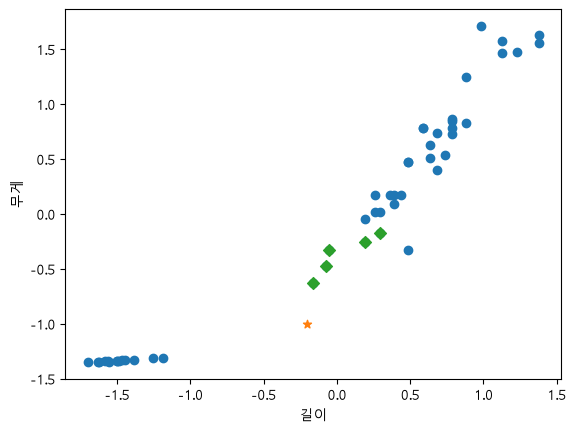

In [13]:
plt.scatter(train_scaled[:,0], train_scaled[:,1])
plt.scatter(new_data[0],new_data[1],marker='*')
plt.scatter(train_data[indexes,0], train_data[indexes,1], marker='D')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [14]:
clf = KNeighborsClassifier()
clf.fit(train_data, train_label)

result = clf.predict(test_data)

score = metrics.accuracy_score(result,test_label)
score = clf.score(test_data,test_label)
print('예측 :', score)

예측 : 1.0


In [15]:
# result2 = clf.predict([[29.5, 300]])
# print('예측 : ', result2)

# result3 = clf.predict([[25, 150]])
# print('예측 : ', result3)

result2 = clf.predict([[29.5, 300]])
print('예측 : ', result2)
result3 = clf.predict([[25, 150]])
print('예측 : ', result3)

distance, indexes = clf.kneighbors([[25, 120]]) # 
distance
indexes


예측 :  [1]
예측 :  [1]


array([[25, 29, 34, 23, 30]])

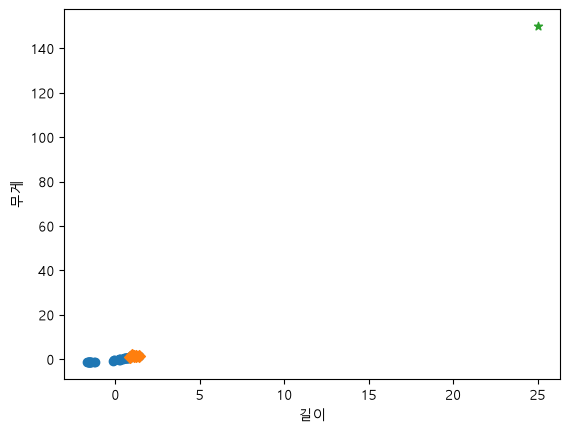

In [16]:
plt.scatter(train_data[:,0], train_data[:,1])
plt.scatter(train_data[indexes,0], train_data[indexes,1], marker='D')
# plt.scatter(29.5, 300, marker='^')
plt.scatter(25, 150, marker='*')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()


In [17]:
plt.scatter

<function matplotlib.pyplot.scatter(x: 'float | ArrayLike', y: 'float | ArrayLike', s: 'float | ArrayLike | None' = None, c: 'ArrayLike | Sequence[ColorType] | ColorType | None' = None, *, marker: 'MarkerType | None' = None, cmap: 'str | Colormap | None' = None, norm: 'str | Normalize | None' = None, vmin: 'float | None' = None, vmax: 'float | None' = None, alpha: 'float | None' = None, linewidths: 'float | Sequence[float] | None' = None, edgecolors: "Literal['face', 'none'] | ColorType | Sequence[ColorType] | None" = None, colorizer: 'Colorizer | None' = None, plotnonfinite: 'bool' = False, data: 'DataParamType' = None, **kwargs) -> 'PathCollection'>